# Lab 13-02 · Electrostatics: Boundary-Value Problems

Companion to [chapter 13-02](../../chapters/13-02-electrostatics-boundary-value-problems.md). Four parts: a finite-difference solution of the square trough against the Fourier series; the capacitance of a strip over a ground plane, with fringing, from the stored energy; the charge induced on a ground plane by a point charge; and the refraction of field lines at a dielectric interface. Run the cells in order.

In [1]:
import math
import numpy as np
import scipy.sparse as sps
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
e0 = 8.8541878128e-12

def laplace_fd(nx, ny, top=1.0):
    '''Sparse finite-difference Laplace on an nx x ny interior grid (equal spacing), top edge at `top`, others 0.'''
    N = nx * ny
    rows, cols, vals, rhs = [], [], [], np.zeros(N)
    for j in range(ny):
        for i in range(nx):
            p = j * nx + i
            rows.append(p); cols.append(p); vals.append(-4.0)
            for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                ii, jj = i + di, j + dj
                if 0 <= ii < nx and 0 <= jj < ny:
                    rows.append(p); cols.append(jj * nx + ii); vals.append(1.0)
                elif jj == ny:
                    rhs[p] -= top
    return spla.spsolve(sps.csr_matrix((vals, (rows, cols)), shape=(N, N)), rhs).reshape(ny, nx)

def series(x, y, nterms=400):
    s = 0.0
    for n in range(1, 2 * nterms, 2):
        ky, kb = n * math.pi * y, n * math.pi
        s += 4 / (n * math.pi) * math.exp(ky - kb) * (1 - math.exp(-2 * ky)) / (1 - math.exp(-2 * kb)) * math.sin(n * math.pi * x)
    return s

## Part 1 · Finite differences against the series

**Predict first:** the stencil's error is $O(h^2)$. On log axes, what slope should the error at $(a/2, 3a/4)$ have against the grid spacing? (Spacings that put a node exactly at that point are used.)

h = a/  8: V = 0.536080, error 4.45e-03
h = a/ 16: V = 0.539325, error 1.20e-03
h = a/ 32: V = 0.540222, error 3.07e-04
h = a/ 64: V = 0.540452, error 7.72e-05
h = a/128: V = 0.540510, error 1.93e-05


fitted slope 1.97; centre value on the finest grid 0.250000


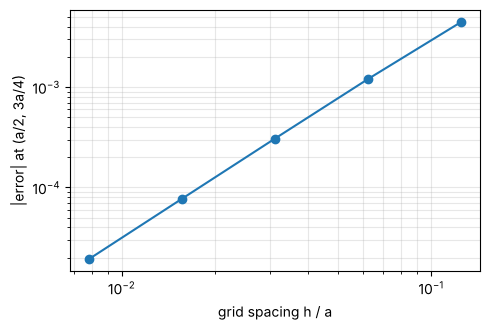

In [2]:
exact = series(0.5, 0.75)
hs, errs = [], []
for m in (8, 16, 32, 64, 128):            # spacing a/m
    V = laplace_fd(m - 1, m - 1)
    val = V[int(0.75 * m) - 1, m // 2 - 1]
    hs.append(1 / m); errs.append(abs(val - exact))
    print(f"h = a/{m:3d}: V = {val:.6f}, error {abs(val - exact):.2e}")
slope = np.polyfit(np.log(hs), np.log(errs), 1)[0]
print(f"fitted slope {slope:.2f}; centre value on the finest grid {laplace_fd(127, 127)[63, 63]:.6f}")
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(hs, errs, 'o-'); ax.set_xlabel('grid spacing h / a'); ax.set_ylabel('|error| at (a/2, 3a/4)'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Part 2 · A strip over a ground plane

A zero-thickness strip of width $w$ at height $h$ over a ground plane, inside a grounded box 20$h$ wide and 10$h$ tall, solved on a grid of spacing $h/30$. The capacitance per length comes from the stored energy, $C' = 2W'_e/V^2$. The fringing factor divides it by the parallel-plate value $\varepsilon_0w/h$.

w/h =  0.5: C' =  20.94 pF/m, fringing factor 4.730


w/h =    1: C' =  26.89 pF/m, fringing factor 3.037


w/h =    2: C' =  38.16 pF/m, fringing factor 2.155


w/h =    5: C' =  69.23 pF/m, fringing factor 1.564


w/h =   10: C' = 119.34 pF/m, fringing factor 1.348


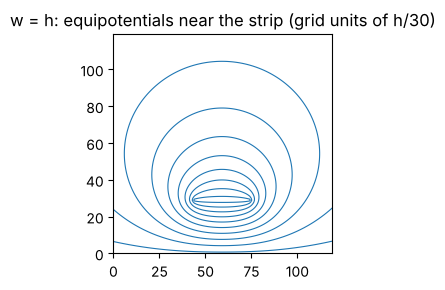

In [3]:
def strip_cap(w_over_h, n=30, box_w=20, box_h=10):
    nx, ny = box_w * n - 1, box_h * n - 1
    N = nx * ny
    js, half, ic = n - 1, int(round(w_over_h * n / 2)), nx // 2
    strip = set(range(ic - half, ic + half + 1))
    rows, cols, vals, rhs = [], [], [], np.zeros(N)
    for j in range(ny):
        for i in range(nx):
            p = j * nx + i
            if j == js and i in strip:
                rows.append(p); cols.append(p); vals.append(1.0); rhs[p] = 1.0
                continue
            rows.append(p); cols.append(p); vals.append(-4.0)
            for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                ii, jj = i + di, j + dj
                if 0 <= ii < nx and 0 <= jj < ny:
                    rows.append(p); cols.append(jj * nx + ii); vals.append(1.0)
    V = spla.spsolve(sps.csr_matrix((vals, (rows, cols)), shape=(N, N)), rhs).reshape(ny, nx)
    Vf = np.pad(V, 1)
    W = 0.5 * e0 * (np.sum(np.diff(Vf, axis=1) ** 2) + np.sum(np.diff(Vf, axis=0) ** 2))
    return 2 * W, V

for wh in (0.5, 1, 2, 5, 10):
    C, _ = strip_cap(wh)
    print(f"w/h = {wh:4}: C' = {C * 1e12:6.2f} pF/m, fringing factor {C / (e0 * wh):.3f}")
C1, V1 = strip_cap(1.0)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.contour(V1[:120, 240:360], levels=np.linspace(0.05, 0.95, 10), colors='C0', linewidths=0.8)
ax.set_aspect('equal'); ax.set_title('w = h: equipotentials near the strip (grid units of h/30)'); plt.tight_layout(); plt.show()

## Part 3 · A point charge above a ground plane

The image solution gives $\rho_s(r) = -Qh/[2\pi(r^2 + h^2)^{3/2}]$. Integrate it over discs of growing radius. **Predict first:** how large a disc holds 99% of the induced charge?

R =   0.5 h:  10.56% of the induced charge
R =     1 h:  29.29% of the induced charge
R =     2 h:  55.28% of the induced charge
R =     5 h:  80.39% of the induced charge
R =    10 h:  90.05% of the induced charge
R =   100 h:  99.21% of the induced charge


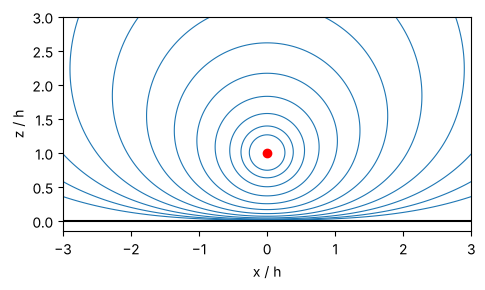

In [4]:
from scipy.integrate import quad
Q, h = 1e-9, 1e-2
rho_s = lambda r: -Q * h / (2 * math.pi * (r * r + h * h) ** 1.5)
for R in (0.5, 1, 2, 5, 10, 100):
    frac = quad(lambda r: rho_s(r) * 2 * math.pi * r, 0, R * h)[0] / -Q
    print(f"R = {R:5} h: {100 * frac:6.2f}% of the induced charge")
xg, zg = np.meshgrid(np.linspace(-3, 3, 241) * h, np.linspace(0.01, 3, 200) * h)
Vp = 1 / (4 * math.pi * e0) * (Q / np.hypot(xg, zg - h) - Q / np.hypot(xg, zg + h))
fig, ax = plt.subplots(figsize=(6, 3))
ax.contour(xg / h, zg / h, Vp, levels=np.geomspace(20, 3000, 12), colors='C0', linewidths=0.8)
ax.axhline(0, color='k'); ax.plot(0, 1, 'ro'); ax.set_xlabel('x / h'); ax.set_ylabel('z / h'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

## Part 4 · Refraction at a dielectric interface

A field line meets the interface at 40° from the normal in air. In the dielectric, $\tan\theta_2 = (\varepsilon_2/\varepsilon_1)\tan\theta_1$.

eps_r =   1: angle from the normal  40.0 deg, E_n ratio 1/1
eps_r =   2: angle from the normal  59.2 deg, E_n ratio 1/2
eps_r =   4: angle from the normal  73.4 deg, E_n ratio 1/4
eps_r =  10: angle from the normal  83.2 deg, E_n ratio 1/10


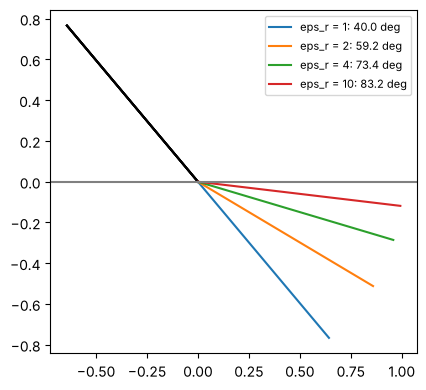

In [5]:
th1 = math.radians(40)
fig, ax = plt.subplots(figsize=(5, 4))
for er in (1, 2, 4, 10):
    th2 = math.atan(er * math.tan(th1))
    ax.plot([-math.sin(th1), 0], [math.cos(th1), 0], 'k')
    ax.plot([0, math.sin(th2)], [0, -math.cos(th2)], label=f'eps_r = {er}: {math.degrees(th2):.1f} deg')
    print(f"eps_r = {er:3}: angle from the normal {math.degrees(th2):5.1f} deg, E_n ratio 1/{er}")
ax.axhline(0, color='gray'); ax.set_aspect('equal'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Discussion.** Part 1's slope is close to 2: halving the spacing quarters the error, the signature of the $O(h^2)$ stencil. Part 2 shows that fringing doubles or triples the capacitance of a strip as wide as its height, which is why microstrip formulas are fits to numerical solutions. Part 3 needs a disc of radius about 100 heights to hold 99% of the induced charge, because the density falls only as $r^{-3}$.